# Ablation Studies

**Owner:** Vikash Kumar. Phase 2, deep learning (notebook 06 of 07).

## Purpose

Find out, with controlled experiments, which design choices drive the accuracy of the deep models on NASA C-MAPSS FD001. One factor is changed at a time from a stated reference configuration, all other settings fixed. Seven ablations are reported: window length, input features, RUL target cap, model capacity, regularization, architecture and hybrid components.

## Method

**Reference configuration.** The LSTM `lstm_v1` of notebook 03: 1 layer, 64 hidden units, dropout 0.2, weight decay 1e-4, window 30, 14 standardised sensors, AdamW at 1e-3, patience 8, uncapped target. It was chosen as the best single deep model by validation-window MAE (26.38 against 26.78 GRU, 27.07 Transformer, 28.86 CNN in `summary_*.csv` and the configs of notebooks 03 and 04).

**Protocol (identical to notebooks 03 and 04).** Split by engine (80 training, 20 validation). The scaler is fitted on the 80 training engines. Training uses all their windows. Early stopping and model selection use the MAE over all windows of the 20 validation engines (`val_window_mae`). The 100 fixed validation points are scored once after training (`point_mae`, `point_rmse`, early and late MAE). Evaluation always uses the true, uncapped RUL; a cap only changes the training target. Runs use CPU, which is deterministic here, and are spread over 6 worker processes (`src/ablation.py`).

> An earlier version of this notebook early-stopped on the 100 reporting points, which made those results about 1 cycle too optimistic (reference seed 42: 18.41 instead of 19.41). All ablation runs below were redone with the protocol above, and the seed 42 reference run reproduces notebook 03 exactly.

**Seeds.** Seeds 42, 43, 44 for every run in this notebook, reported as mean and standard deviation (`ddof=1`).

| Ablation | Settings | Source |
| --- | --- | --- |
| 1 Window length | 10, 20, **30**, 40, 50 cycles | run here (3 seeds) |
| 2 Input features | **14 sensors**, +2 operating settings (16), +14 first differences (28) | run here (3 seeds) |
| 3 RUL target cap | **none**, 125, 150 | run here (3 seeds) |
| 4 Capacity | hidden 32, **64**, 128 x layers **1**, 2, 3 | run here (3 seeds) |
| 5 Regularization | dropout, weight decay, patience, hidden size, layers, gradient clipping for GRU and LSTM; dropout and weight decay for CNN and Transformer | reused from notebooks 03 and 04 (seed 42, `val_window_mae` only) |
| 6 Architecture | LSTM, GRU, CNN, Transformer at their selected configurations | run here (3 seeds) |
| 7 Hybrid components | rolling features only, DL prediction only, rolling + 1 DL, rolling + 2 DL (`hybrid_v1`), average, residual | reused from notebook 05 (`hybrid_variants.csv`, `hybrid_components.csv`) |

Bold marks the reference value. The reference runs are shared between ablations (the same seeds are not trained twice).

**Reading the tables.** `delta` is the change of `point_mae` against the reference of that ablation. A difference smaller than the pooled standard deviation of the two settings, $\sqrt{(s_1^2+s_2^2)/2}$, is called *not distinguishable from noise*. With 3 seeds and 100 points from 20 engines these standard deviations are rough, so small differences should not be over-read.

**Compute budget.** About 60 training runs. The cache `results/phase2/ablation_results.csv` stores one row per run, and the notebook skips runs already present, so an interrupted run resumes and a finished one re-executes in seconds.

## Results

### Setup

Imports, paths and plotting defaults. `ROOT` is found from the working directory, so the notebook must run from `notebooks/phase2/`.

In [1]:
import json
import sys
import time
from pathlib import Path

ROOT = Path.cwd().resolve().parents[1]  # run from notebooks/phase2
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import ablation as ab

RESULTS = ROOT / "results" / "phase2"
FIGS = RESULTS / "figures"
FIGS.mkdir(parents=True, exist_ok=True)
CACHE = RESULTS / "ablation_results.csv"
WORKERS = 6
SEEDS = (42, 43, 44)
plt.rcParams.update({"savefig.dpi": 150, "font.size": 10, "axes.grid": True, "grid.alpha": 0.3})


def save_fig(fig, name):
    # Save a figure under results/phase2/figures and show it.
    fig.tight_layout()
    fig.savefig(FIGS / name, bbox_inches="tight")
    plt.show()

### Experiment plan

Define every run. `lstm_ref` is the reference. The reference runs for window 30, 14 sensors, no cap, hidden 64 x 1 layer and `lstm_v1` are the same runs, so they are trained once (`window_30`) and copied into the other ablations afterwards.

In [2]:
LSTM_REF = dict(model="lstm", kw=dict(hidden=64, layers=1, dropout=0.2))


def cfg(ablation, setting, seed, **overrides):
    return {"ablation": ablation, "setting": setting, "seed": seed, **{**LSTM_REF, **overrides}}


plan = []
for s in SEEDS:
    for w in (10, 20, 30, 40, 50):
        plan.append(cfg("window", f"window_{w}", s, window=w))
    plan.append(cfg("features", "16_with_settings", s, features="settings"))
    plan.append(cfg("features", "28_with_diff", s, features="diff"))
    for cap in (125, 150):
        plan.append(cfg("rul_cap", f"cap_{cap}", s, rul_cap=cap))
    for h in (32, 64, 128):
        for layers in (1, 2, 3):
            if (h, layers) != (64, 1):
                plan.append(cfg("capacity", f"h{h}_l{layers}", s, kw=dict(hidden=h, layers=layers, dropout=0.2)))
    # architecture: the selected configuration of every model, read from its config file
    for name in ("gru_v1", "cnn1d_v1", "transformer_v1"):
        c = json.loads((RESULTS / f"config_{name.split('_')[0]}.json").read_text())
        kind = c["kind"]
        kw = c["kwargs"] if "kwargs" in c else {k: c[k] for k in ("hidden", "layers", "dropout")}
        plan.append(cfg("architecture", name, s, model=kind, kw=kw, lr=c["lr"], weight_decay=c["weight_decay"]))
print(f"{len(plan)} runs planned (cached runs are skipped)")

60 runs planned (cached runs are skipped)


### Run the ablations

In [3]:
start = time.perf_counter()
cache_df = ab.run_missing(plan, CACHE, workers=WORKERS)
print(f"cache holds {len(cache_df)} rows; this execution took {time.perf_counter() - start:.0f} s")

cache holds 144 rows; this execution took 0 s


Add the shared reference runs to the ablations that use them, and the reused results of notebooks 03, 04 and 05 (marked in the `source` column). Then save the full table and the summary.

In [4]:
run_rows = cache_df[cache_df["source"] == "run"].copy()
ref = run_rows[run_rows["setting"] == "window_30"]
copies = []
for ablation, setting in (("features", "14_sensors"), ("rul_cap", "no_cap"), ("capacity", "h64_l1"), ("architecture", "lstm_v1"), ("hybrid_components", "LSTM alone (3 seeds, window_30 runs)")):
    c = ref.copy()
    c["ablation"], c["setting"], c["source"] = ablation, setting, "reference run (window_30)"
    copies.append(c)

# regularization: reuse notebook 03 (GRU, LSTM) and notebook 04 (CNN, Transformer); seed 42, window MAE only
reg = []
rnn = pd.read_csv(RESULTS / "rnn_regularization.csv")
for _, r in rnn.iterrows():
    reg.append({"ablation": "regularization", "setting": f"{r['model']}_{r['factor']}_{r['value']}", "seed": 42,
                "val_window_mae": r["val_window_mae"], "epochs_run": r["epochs_run"], "source": "notebook 03 (rnn_regularization.csv)"})
ct = pd.read_csv(RESULTS / "cnn_transformer_regularization.csv")
for _, r in ct[ct["factor"].isin(["dropout", "weight_decay", "baseline"])].iterrows():
    reg.append({"ablation": "regularization", "setting": f"{r['model']}_{r['factor']}_{r['value']}", "seed": 42,
                "val_window_mae": r["val_window_mae"], "epochs_run": r["epochs_run"], "source": "notebook 04 (cnn_transformer_regularization.csv)"})

# hybrid components: reuse notebook 05 (3 seeds, except the DL-only run which has seed 42 only)
hv = pd.read_csv(RESULTS / "hybrid_variants.csv")
names = {"RF (Phase 1)": "rolling only (RF)", "A-RF": "rolling + 1 DL", "A-RF-2DL": "rolling + 2 DL (hybrid_v1)",
         "B": "average (B)", "C-RF": "residual (C)"}
hyb = []
for _, r in hv[hv["model"].isin(names)].iterrows():
    hyb.append({"ablation": "hybrid_components", "setting": names[r["model"]], "seed": int(r["seed"]), "val_window_mae": r["window_mae"],
                "point_mae": r["mae"], "point_rmse": r["rmse"], "early_mae": r["early_mae"], "late_mae": r["late_mae"],
                "source": "notebook 05 (hybrid_variants.csv)"})
dl_only = pd.read_csv(RESULTS / "hybrid_components.csv").set_index("components").loc["DL only"]
hyb.append({"ablation": "hybrid_components", "setting": "DL prediction only", "seed": 42, "val_window_mae": dl_only["window_mae"],
            "point_mae": dl_only["mae"], "point_rmse": dl_only["rmse"], "early_mae": dl_only["early_mae"], "late_mae": dl_only["late_mae"],
            "source": "notebook 05 (hybrid_components.csv)"})

full = pd.concat([run_rows, *copies, pd.DataFrame(reg), pd.DataFrame(hyb)], ignore_index=True)[ab.RESULT_COLUMNS]
assert not full.duplicated(ab.KEYS).any()
full.to_csv(CACHE, index=False)
summary = ab.summarize(full)
summary.to_csv(RESULTS / "ablation_summary.csv", index=False)
print(f"ablation_results.csv: {len(full)} rows | ablation_summary.csv: {len(summary)} settings")
print(full.groupby(["ablation", "source"]).size().to_string())

ablation_results.csv: 144 rows | ablation_summary.csv: 84 settings
ablation           source                                          
architecture       reference run (window_30)                            3
                   run                                                  9
capacity           reference run (window_30)                            3
                   run                                                 24
features           reference run (window_30)                            3
                   run                                                  6
hybrid_components  notebook 05 (hybrid_components.csv)                  1
                   notebook 05 (hybrid_variants.csv)                   15
                   reference run (window_30)                            3
regularization     notebook 03 (rnn_regularization.csv)                40
                   notebook 04 (cnn_transformer_regularization.csv)    13
rul_cap            reference run (window_30)       

Check that the seed 42 reference run reproduces the LSTM of notebook 03 and that the other three architectures reproduce notebooks 03 and 04. This is the determinism and protocol check for this notebook.

In [5]:
reported = pd.concat([pd.read_csv(RESULTS / "summary_rnn.csv"), pd.read_csv(RESULTS / "summary_cnn_transformer.csv")]).set_index("model")
arch42 = full[(full["ablation"] == "architecture") & (full["seed"] == 42)].set_index("setting")
check = pd.DataFrame({"this notebook (seed 42)": arch42["point_mae"], "reported (seed 42)": reported["mae"]}).dropna()
check["abs_diff"] = (check.iloc[:, 0] - check.iloc[:, 1]).abs()
print(check.round(3).to_string())
assert (check["abs_diff"] < 0.01).all(), "ablation runs do not reproduce the model notebooks"

                this notebook (seed 42)  reported (seed 42)  abs_diff
cnn1d_v1                         24.323              24.323       0.0
gru_v1                           23.175              23.175       0.0
lstm_v1                          19.408              19.408       0.0
transformer_v1                   20.589              20.589       0.0


### Helper: effect against the reference with the noise rule

For an ablation, show mean and standard deviation of the 100-point MAE and RMSE and the validation-window MAE per setting, the change against the reference, and whether the change is smaller than the pooled standard deviation.

In [6]:
def effect_table(ablation, reference, order=None):
    s = summary[summary["ablation"] == ablation].set_index("setting")
    if order is not None:
        s = s.loc[order]
    ref_row = s.loc[reference]
    out = s[["n_seeds", "point_mae_mean", "point_mae_std", "point_rmse_mean", "point_rmse_std", "val_window_mae_mean"]].copy()
    out["delta_mae"] = out["point_mae_mean"] - ref_row["point_mae_mean"]
    pooled = np.sqrt((out["point_mae_std"] ** 2 + ref_row["point_mae_std"] ** 2) / 2)
    out["pooled_std"] = pooled
    out["verdict"] = np.where(out.index == reference, "reference", np.where(pooled.isna(), "single run (no spread)",
                              np.where(out["delta_mae"].abs() < pooled, "within noise", np.where(out["delta_mae"] < 0, "better", "worse"))))
    return out


def show(df):
    print(df.round(2).to_string())

### Ablation 1: window length

           n_seeds  point_mae_mean  point_mae_std  point_rmse_mean  point_rmse_std  val_window_mae_mean  delta_mae  pooled_std       verdict
setting                                                                                                                                     
window_10        3           27.60           0.81            39.64            0.67                29.59       7.46        1.18         worse
window_20        3           23.39           1.01            33.50            0.34                28.34       3.25        1.26         worse
window_30        3           20.14           1.46            33.18            2.46                26.92       0.00        1.46     reference
window_40        3           20.93           0.57            36.23            1.29                26.53       0.79        1.11  within noise
window_50        3           21.24           0.64            35.72            1.65                26.86       1.10        1.13  within noise


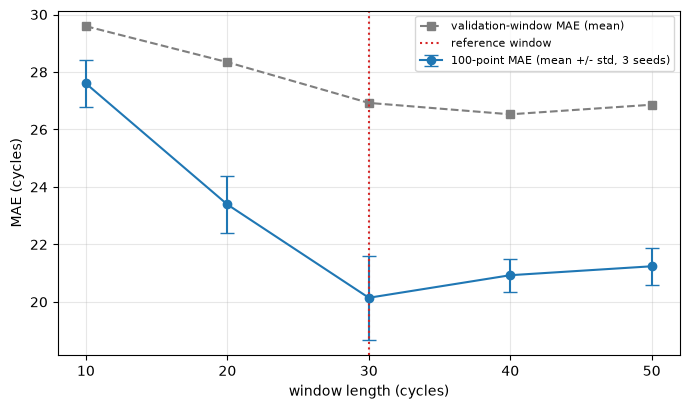

In [7]:
t1 = effect_table("window", "window_30", ["window_10", "window_20", "window_30", "window_40", "window_50"])
show(t1)
fig, ax = plt.subplots(figsize=(7, 4.2))
xs = [10, 20, 30, 40, 50]
ax.errorbar(xs, t1["point_mae_mean"], yerr=t1["point_mae_std"], marker="o", capsize=5, color="#1f77b4", label="100-point MAE (mean +/- std, 3 seeds)")
ax.plot(xs, t1["val_window_mae_mean"], marker="s", ls="--", color="#7f7f7f", label="validation-window MAE (mean)")
ax.axvline(30, color="#d62728", ls=":", label="reference window")
ax.set_xlabel("window length (cycles)"); ax.set_ylabel("MAE (cycles)"); ax.set_xticks(xs); ax.legend(fontsize=8)
save_fig(fig, "ablation_window.png")

*Figure: effect of the window length on validation MAE (LSTM reference, 3 seeds).*

### Ablation 2: input features

                  n_seeds  point_mae_mean  point_mae_std  point_rmse_mean  point_rmse_std  val_window_mae_mean  delta_mae  pooled_std       verdict
setting                                                                                                                                            
14_sensors              3           20.14           1.46            33.18            2.46                26.92       0.00        1.46     reference
16_with_settings        3           21.88           2.07            35.29            1.33                28.34       1.74        1.79  within noise
28_with_diff            3           23.18           0.41            38.03            2.71                28.23       3.03        1.07         worse


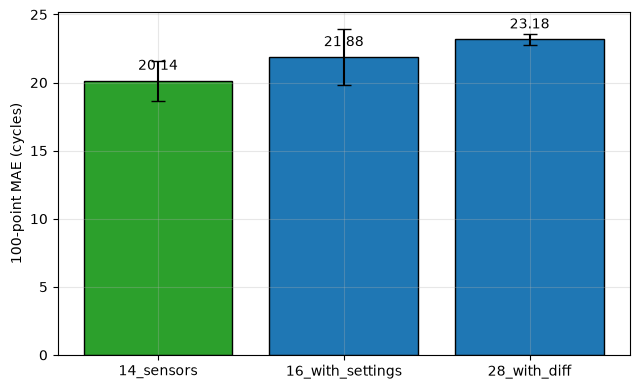

In [8]:
t2 = effect_table("features", "14_sensors", ["14_sensors", "16_with_settings", "28_with_diff"])
show(t2)
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.bar(range(3), t2["point_mae_mean"], yerr=t2["point_mae_std"], capsize=5, color=["#2ca02c", "#1f77b4", "#1f77b4"], edgecolor="black")
ax.set_xticks(range(3), t2.index); ax.set_ylabel("100-point MAE (cycles)")
for i, v in enumerate(t2["point_mae_mean"]):
    ax.text(i, v + 0.8, f"{v:.2f}", ha="center")
save_fig(fig, "ablation_features.png")

*Figure: effect of the input channels (14 sensors, plus 2 operating settings, plus 14 first differences) on validation MAE.*

### Ablation 3: RUL target cap

         n_seeds  point_mae_mean  point_mae_std  point_rmse_mean  point_rmse_std  val_window_mae_mean  delta_mae  pooled_std    verdict
setting                                                                                                                                
no_cap         3           20.14           1.46            33.18            2.46                26.92       0.00        1.46  reference
cap_125        3           22.27           0.70            39.36            0.84                33.68       2.13        1.15      worse
cap_150        3           21.92           1.15            36.28            0.41                29.75       1.78        1.32      worse


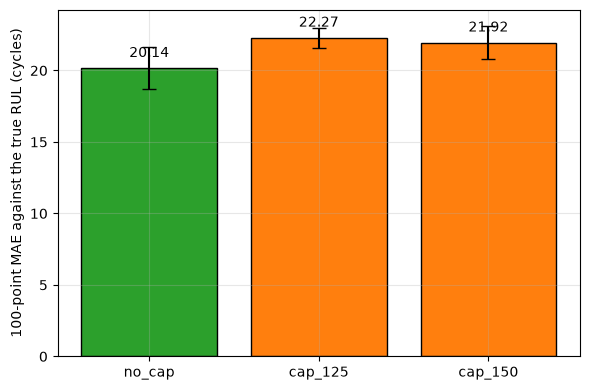

In [9]:
t3 = effect_table("rul_cap", "no_cap", ["no_cap", "cap_125", "cap_150"])
show(t3)
fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(range(3), t3["point_mae_mean"], yerr=t3["point_mae_std"], capsize=5, color=["#2ca02c", "#ff7f0e", "#ff7f0e"], edgecolor="black")
ax.set_xticks(range(3), t3.index); ax.set_ylabel("100-point MAE against the true RUL (cycles)")
for i, v in enumerate(t3["point_mae_mean"]):
    ax.text(i, v + 0.8, f"{v:.2f}", ha="center")
save_fig(fig, "ablation_rul_cap.png")

*Figure: effect of capping the training target. Evaluation always uses the true, uncapped RUL.*

### Ablation 4: capacity

         n_seeds  point_mae_mean  point_mae_std  point_rmse_mean  point_rmse_std  val_window_mae_mean  delta_mae  pooled_std       verdict
setting                                                                                                                                   
h32_l1         3           20.92           0.24            34.18            1.39                27.13       0.78        1.05  within noise
h32_l2         3           23.53           1.03            35.90            2.67                28.02       3.39        1.27         worse
h32_l3         3           23.76           0.28            37.32            1.30                28.64       3.61        1.05         worse
h64_l1         3           20.14           1.46            33.18            2.46                26.92       0.00        1.46     reference
h64_l2         3           21.88           1.18            33.91            0.10                28.25       1.74        1.33         worse
h64_l3         3           

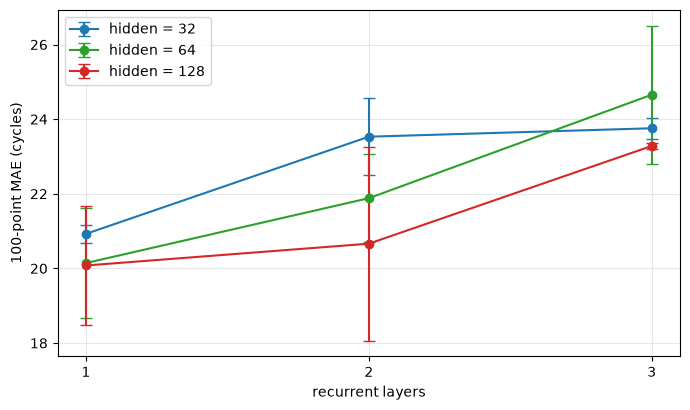

In [10]:
order = [f"h{h}_l{l}" for h in (32, 64, 128) for l in (1, 2, 3)]
t4 = effect_table("capacity", "h64_l1", order)
show(t4)
pivot = t4["point_mae_mean"].to_frame()
pivot["hidden"] = [int(s[1:].split("_")[0]) for s in pivot.index]
pivot["layers"] = [int(s.split("_l")[1]) for s in pivot.index]
print("\nMAE grid (hidden x layers):")
print(pivot.pivot(index="hidden", columns="layers", values="point_mae_mean").round(2).to_string())
fig, ax = plt.subplots(figsize=(7, 4.2))
for h, color in zip((32, 64, 128), ("#1f77b4", "#2ca02c", "#d62728")):
    sub = t4[[s.startswith(f"h{h}_") for s in t4.index]]
    ax.errorbar([1, 2, 3], sub["point_mae_mean"], yerr=sub["point_mae_std"], marker="o", capsize=4, color=color, label=f"hidden = {h}")
ax.set_xticks([1, 2, 3]); ax.set_xlabel("recurrent layers"); ax.set_ylabel("100-point MAE (cycles)"); ax.legend()
save_fig(fig, "ablation_capacity.png")

*Figure: LSTM capacity grid (hidden size by number of layers), mean and standard deviation over 3 seeds.*

### Ablation 5: regularization (reused from notebooks 03 and 04)

These rows are single seed 42 runs scored by the validation-window MAE only (the quantity those notebooks used for selection), so they are not mixed with the 100-point numbers of the other ablations.

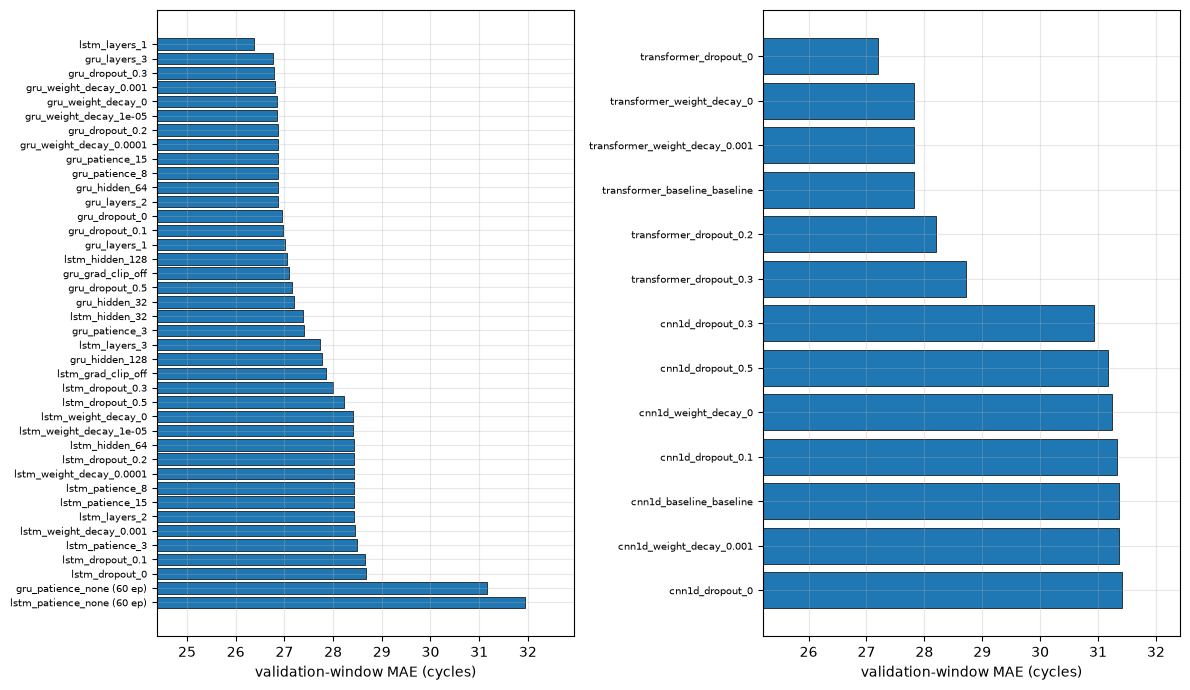

setting
gru_patience_none (60 ep)     31.15
lstm_patience_none (60 ep)    31.95
gru: patience 8 26.87, spread over dropout 0.38, over weight decay 0.07
lstm: patience 8 28.42, spread over dropout 0.68, over weight decay 0.04


In [11]:
reg_view = summary[summary["ablation"] == "regularization"][["setting", "val_window_mae_mean"]].set_index("setting")["val_window_mae_mean"]
fig, axes = plt.subplots(1, 2, figsize=(12, 7))
for ax, prefix in zip(axes, (("gru", "lstm"), ("cnn1d", "transformer"))):
    sub = reg_view[[s.startswith(prefix) for s in reg_view.index]].sort_values()
    ax.barh(range(len(sub)), sub.values, color="#1f77b4", edgecolor="black", linewidth=0.5)
    ax.set_yticks(range(len(sub)), sub.index, fontsize=7); ax.invert_yaxis()
    ax.set_xlabel("validation-window MAE (cycles)"); ax.set_xlim(sub.min() - 2, sub.max() + 1)
save_fig(fig, "ablation_regularization.png")
no_es = reg_view[[("patience_none" in s) for s in reg_view.index]]
print(no_es.round(2).to_string())
for model in ("gru", "lstm"):
    base = reg_view[f"{model}_patience_8"]
    print(f"{model}: patience 8 {base:.2f}, spread over dropout {reg_view[[s.startswith(model + '_dropout') for s in reg_view.index]].agg(lambda v: v.max() - v.min()):.2f}, "
          f"over weight decay {reg_view[[s.startswith(model + '_weight_decay') for s in reg_view.index]].agg(lambda v: v.max() - v.min()):.2f}")

*Figure: validation-window MAE of every regularization setting of the GRU and LSTM (left) and the CNN and Transformer (right), seed 42.*

### Ablation 6: architecture (3 seeds, selected configurations)

                n_seeds  point_mae_mean  point_mae_std  point_rmse_mean  point_rmse_std  val_window_mae_mean  delta_mae  pooled_std    verdict
setting                                                                                                                                       
lstm_v1               3           20.14           1.46            33.18            2.46                26.92       0.00        1.46  reference
gru_v1                3           22.98           0.49            36.61            0.90                27.00       2.84        1.09      worse
cnn1d_v1              3           24.38           0.14            36.86            0.17                29.46       4.24        1.04      worse
transformer_v1        3           22.80           2.28            36.97            2.60                27.18       2.65        1.91      worse


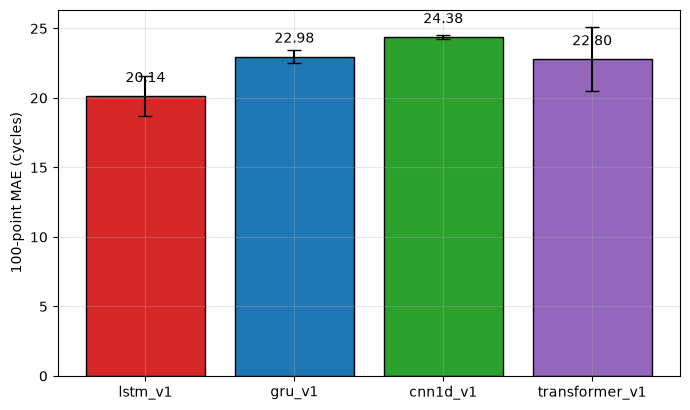

In [12]:
t6 = effect_table("architecture", "lstm_v1", ["lstm_v1", "gru_v1", "cnn1d_v1", "transformer_v1"])
show(t6)
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.bar(range(4), t6["point_mae_mean"], yerr=t6["point_mae_std"], capsize=5, edgecolor="black",
       color=["#d62728", "#1f77b4", "#2ca02c", "#9467bd"])
ax.set_xticks(range(4), t6.index); ax.set_ylabel("100-point MAE (cycles)")
for i, v in enumerate(t6["point_mae_mean"]):
    ax.text(i, v + 1.0, f"{v:.2f}", ha="center")
save_fig(fig, "ablation_architecture.png")

*Figure: the four architectures at their selected configurations, mean and standard deviation over seeds 42, 43, 44.*

### Ablation 7: hybrid components (reused from notebook 05)

                                      n_seeds  point_mae_mean  point_mae_std  point_rmse_mean  point_rmse_std  val_window_mae_mean  delta_mae  pooled_std                 verdict
setting                                                                                                                                                                          
rolling only (RF)                           3           25.08           0.08            40.31            0.15                27.77       0.00        0.08               reference
DL prediction only                          1           24.93            NaN            38.10             NaN                28.72      -0.15         NaN  single run (no spread)
rolling + 1 DL                              3           23.54           0.48            37.18            1.55                26.38      -1.54        0.34                  better
rolling + 2 DL (hybrid_v1)                  3           21.72           0.31            35.34            0.91 

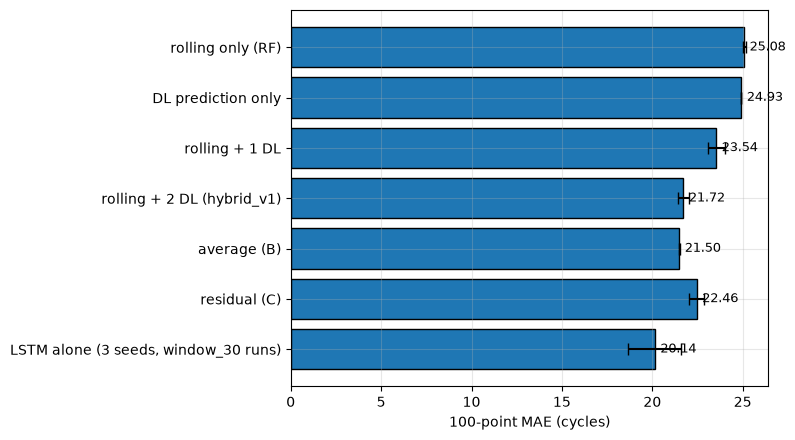

In [13]:
t7 = effect_table("hybrid_components", "rolling only (RF)",
                  ["rolling only (RF)", "DL prediction only", "rolling + 1 DL", "rolling + 2 DL (hybrid_v1)", "average (B)", "residual (C)", "LSTM alone (3 seeds, window_30 runs)"])
show(t7)
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(range(len(t7)), t7["point_mae_mean"], xerr=t7["point_mae_std"].fillna(0), capsize=4, color="#1f77b4", edgecolor="black")
ax.set_yticks(range(len(t7)), t7.index); ax.invert_yaxis(); ax.set_xlabel("100-point MAE (cycles)")
for i, v in enumerate(t7["point_mae_mean"]):
    ax.text(v + 0.3, i, f"{v:.2f}", va="center", fontsize=9)
save_fig(fig, "ablation_hybrid_components.png")

*Figure: 100-point MAE of the hybrid variants and their parts (3 seeds; the DL-only row is a single run and has no error bar). `rolling only (RF)` is the Phase 1 Random Forest.*

### Outputs

The notebook wrote `results/phase2/ablation_results.csv` (one row per run or reused result), `results/phase2/ablation_summary.csv` (mean and standard deviation per setting) and the seven `ablation_*.png` figures.

## Conclusion

All numbers are printed above and stored in `ablation_results.csv` and `ablation_summary.csv`. Reference: `lstm_v1`, 100-point MAE $20.14 \pm 1.46$ (3 seeds). "Within noise" means the change is smaller than the pooled standard deviation of the two settings, which is itself rough with 3 seeds.

1. **Window length matters up to about 30 cycles.** MAE is $27.60 \pm 0.81$ at 10 cycles and $23.39 \pm 1.01$ at 20, both clearly worse than 30 ($20.14 \pm 1.46$). Windows of 40 ($20.93 \pm 0.57$) and 50 ($21.24 \pm 0.64$) are not distinguishable from 30, so 30 is the shortest window on the plateau, not a proven optimum.
2. **Raw sensors are enough.** Adding the two operating settings changes MAE by $+1.74$ (within noise, $21.88 \pm 2.07$). Adding first differences is worse ($23.18 \pm 0.41$, $+3.03$): the recurrent network can form differences itself.
3. **Capping the target hurts under uncapped evaluation.** Cap 125 gives $22.27 \pm 0.70$ ($+2.13$) and cap 150 gives $21.92 \pm 1.15$ ($+1.78$); the validation-window MAE against the true RUL rises from 26.92 to 33.68 and 29.75. A capped model cannot predict above its cap, and 22 of the 100 points have a true RUL above 125. Capping is common in the literature (notebook 01), but it does not help here, and it does not fix the high-RUL gap either.
4. **One layer is best.** At every hidden size the single-layer LSTM is the best or within noise of the best; hidden size at one layer makes no distinguishable difference (32: $+0.78$, 128: $-0.07$). Depth hurts: for hidden 32 two and three layers are $+3.39$ and $+3.61$, for hidden 64 $+1.74$ and $+4.51$, for hidden 128 $+0.52$ (within noise) and $+3.14$. With about 80 independent engines, extra capacity overfits.
5. **Early stopping is the regularizer that matters** (reused from notebooks 03 and 04, seed 42, validation-window MAE). Without it, MAE rises from 26.87 to 31.15 (GRU) and from 28.42 to 31.95 (LSTM). The spread over all tested dropout values is 0.38 (GRU) and 0.68 (LSTM) and over weight decay 0.07 and 0.04, which is below the seed noise of 0.4 to 0.8 cycles.
6. **Architecture.** LSTM $20.14 \pm 1.46$, Transformer $22.80 \pm 2.28$, GRU $22.98 \pm 0.49$, CNN $24.38 \pm 0.14$. On the validation-window MAE (all windows of the 20 validation engines) the first three are close (26.92, 27.00, 27.18) and only the CNN is clearly behind (29.46), so the ordering of LSTM, GRU and Transformer on the 100 points is partly sampling noise. The LSTM is also the cheapest per epoch (notebook 04).
7. **Hybrid.** Every hybrid is better than the Random Forest on rolling features alone ($25.08 \pm 0.08$): rolling + 1 DL estimate $23.54 \pm 0.48$, rolling + 2 DL estimates (`hybrid_v1`) $21.72 \pm 0.31$, average $21.50 \pm 0.03$, residual $22.46 \pm 0.40$. The DL estimate alone, one run without a seed spread, gives 24.93. None beats the LSTM on its own ($20.14 \pm 1.46$), and stacking is no better than the plain average. The hybrid therefore improves a tree model but does not improve the best deep model.

**Caveats.** Three seeds give rough standard deviations; the 100 points come from 20 engines; the regularization and hybrid rows are reused from other notebooks (single protocol, but seed 42 only for regularization). An earlier version of this notebook early-stopped on the 100 reporting points and reported a reference of 19.39; the corrected protocol gives 20.14.

## Handoff

- `results/phase2/ablation_results.csv`, `results/phase2/ablation_summary.csv`
- Figures: `ablation_window.png`, `ablation_features.png`, `ablation_rul_cap.png`, `ablation_capacity.png`, `ablation_regularization.png`, `ablation_architecture.png`, `ablation_hybrid_components.png`